# 实验报告 02：NumPy、SciPy、Matplotlib 与 pandas 数据处理

**姓名：** 金晨曦　　**学号：** 20244081111　　**日期：** 2026-10-20

**运行环境：** conda 虚拟环境 `dpenv`（Python 3.11，NumPy 2.4、SciPy 1.17、Matplotlib 3.11、pandas 3.0）。

本报告按 PDF 中实验 1–4 的顺序完成。所有涉及随机抽样的步骤都固定了随机种子；图表直接在 Notebook 中显示，不保存为文件。

## 一、身份与环境记录

按题目要求，先把第一个代码框中的学号改为自己的学号，再依次运行后续代码框。

In [1]:
import os
import uuid
import hashlib
import platform

import numpy as np
import scipy
import matplotlib
import pandas as pd

# 修改为自己的学号
STUDENT_ID = 20244081111

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号]       {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID]   {RUN_ID}")

[Conda 环境] dpenv
[学号]       20244081111
[机器指纹] 16629dec1dbfab6d
[RUN_ID]   20244081111-16629dec1dbfab6d


In [2]:
import sys

print("Python :", sys.version.split()[0])
print("NumPy  :", np.__version__)
print("SciPy  :", scipy.__version__)
print("Matplotlib:", matplotlib.__version__)
print("pandas :", pd.__version__)

Python : 3.11.17
NumPy  : 2.4.6
SciPy  : 1.17.1
Matplotlib: 3.11.2
pandas : 3.0.6


In [3]:
import matplotlib.pyplot as plt

## 实验 1：NumPy 数组、数据类型与索引

### 1. 三种 dtype 的 ndarray

分别创建整数、浮点数和布尔值 `ndarray`，输出每个数组的 `dtype`、`shape` 和 `ndim`。

In [4]:
int_arr = np.array([1, 2, 3, 4], dtype=np.int64)
float_arr = np.array([1.0, 2.5, 3.14], dtype=np.float64)
bool_arr = np.array([True, False, True, False], dtype=np.bool_)

for name, arr in [("整数数组", int_arr), ("浮点数组", float_arr), ("布尔数组", bool_arr)]:
    print(f"{name}: {arr}")
    print(f"  dtype={arr.dtype}, shape={arr.shape}, ndim={arr.ndim}")

整数数组: [1 2 3 4]
  dtype=int64, shape=(4,), ndim=1
浮点数组: [1.   2.5  3.14]
  dtype=float64, shape=(3,), ndim=1
布尔数组: [ True False  True False]
  dtype=bool, shape=(4,), ndim=1


**说明：** `ndarray` 是同质容器，所有元素共享同一个 `dtype`，在内存中连续存放，因此支持向量化运算；Python `list` 可以存放任意类型的对象，每个元素都是独立对象，没有统一的 `dtype` 和 `shape`，逐元素运算通常需要循环或列表推导。`shape` 表示各维的长度，`ndim` 表示维数；上面三个数组都是一维、长度为 4（布尔数组长度为 4），所以 `ndim` 都是 1。

### 2. `np.arange(12)` 的 reshape

用 `np.arange(12)` 创建一维数组，再分别变为 `(3, 4)` 和 `(2, 3, 2)` 形状，展示数组内容。

In [5]:
base = np.arange(12)
a_2d = base.reshape(3, 4)
a_3d = base.reshape(2, 3, 2)

print("一维数组 base:", base, "shape:", base.shape)
print("\nreshape(3, 4):")
print(a_2d)
print("shape:", a_2d.shape, "ndim:", a_2d.ndim)
print("\nreshape(2, 3, 2):")
print(a_3d)
print("shape:", a_3d.shape, "ndim:", a_3d.ndim)

一维数组 base: [ 0  1  2  3  4  5  6  7  8  9 10 11] shape: (12,)

reshape(3, 4):
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
shape: (3, 4) ndim: 2

reshape(2, 3, 2):
[[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]
shape: (2, 3, 2) ndim: 3


**说明：** `reshape` 只改变数组的“视图”形状，不改变元素的个数和顺序。改变形状时必须满足“新形状各维长度的乘积 = 原数组元素总数”，这里 12 = 3×4 = 2×3×2；否则会抛出 `ValueError`。

### 3. `(3, 4)` 数组的索引

对形状为 `(3, 4)` 的数组分别取第 2 行、第 1 至第 3 列、大于 6 的元素，并输出结果及形状。

In [6]:
m = np.arange(12).reshape(3, 4)
row2 = m[1]                 # 第 2 行（0-based 索引 1）
cols1to3 = m[:, 0:3]        # 第 1 至第 3 列（左闭右开）
gt6 = m[m > 6]              # 布尔索引

print("原矩阵 m:")
print(m)
print("\n第 2 行 m[1]:", row2, "shape:", row2.shape)
print("\n第 1 至第 3 列 m[:, 0:3]:")
print(cols1to3, "shape:", cols1to3.shape)
print("\n大于 6 的元素 m[m > 6]:", gt6, "shape:", gt6.shape)

原矩阵 m:
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

第 2 行 m[1]: [4 5 6 7] shape: (4,)

第 1 至第 3 列 m[:, 0:3]:
[[ 0  1  2]
 [ 4  5  6]
 [ 8  9 10]] shape: (3, 3)

大于 6 的元素 m[m > 6]: [ 7  8  9 10 11] shape: (5,)


**说明：** Python/NumPy 下标从 0 开始，所以“第 2 行”是 `m[1]`，“第 1 至第 3 列”是 `m[:, 0:3]`。基本切片（如 `m[:, 0:3]`）返回的是原数组的视图，形状为 `(3, 3)`；布尔索引 `m[m > 6]` 返回一维副本，元素为 7–11，共 5 个，形状为 `(5,)`。

### 4. 布尔索引与逻辑运算

使用 `np.arange(10)`，分别选出“小于 2 或大于 7”和“大于 3 且小于 7”的元素，比较 `|`、`&` 与 `np.logical_or()`、`np.logical_and()` 的写法。

In [7]:
x = np.arange(10)
mask_or = (x < 2) | (x > 7)
mask_and = (x > 3) & (x < 7)

print("x =", x)
print("x < 2 | x > 7 的掩码:", mask_or.astype(int))
print("满足“小于 2 或大于 7”的元素:", x[mask_or])
print("x > 3 & x < 7 的掩码:", mask_and.astype(int))
print("满足“大于 3 且小于 7”的元素:", x[mask_and])
print("np.logical_or 验证:", np.logical_or(x < 2, x > 7).astype(int))
print("np.logical_and 验证:", np.logical_and(x > 3, x < 7).astype(int))

x = [0 1 2 3 4 5 6 7 8 9]
x < 2 | x > 7 的掩码: [1 1 0 0 0 0 0 0 1 1]
满足“小于 2 或大于 7”的元素: [0 1 8 9]
x > 3 & x < 7 的掩码: [0 0 0 0 1 1 1 0 0 0]
满足“大于 3 且小于 7”的元素: [4 5 6]
np.logical_or 验证: [1 1 0 0 0 0 0 0 1 1]
np.logical_and 验证: [0 0 0 0 1 1 1 0 0 0]


**说明：** 组合条件必须用括号把每个比较包起来，因为 `&`、`|` 的优先级高于比较运算符；写成 `x > 3 & x < 7` 会得到错误结果。`|`/`&` 与 `np.logical_or`/`np.logical_and` 在这里等价，前者更简洁，后者可读性更好。结果分别为 `[0 1 8 9]` 和 `[4 5 6]`。

### 5. 逐元素乘法与矩阵乘法

构造两个 `(2, 2)` 数组，对比 `*`、`np.multiply()` 与 `@`、`np.matmul()` 的结果。

In [8]:
A = np.array([[1, 2],
              [3, 4]])
B = np.array([[5, 6],
              [7, 8]])

print("A:")
print(A)
print("B:")
print(B)
print("\nA * B（逐元素相乘）:")
print(A * B)
print("\nnp.multiply(A, B):")
print(np.multiply(A, B))
print("\nA @ B（矩阵乘法）:")
print(A @ B)
print("\nnp.matmul(A, B):")
print(np.matmul(A, B))

A:
[[1 2]
 [3 4]]
B:
[[5 6]
 [7 8]]

A * B（逐元素相乘）:
[[ 5 12]
 [21 32]]

np.multiply(A, B):
[[ 5 12]
 [21 32]]

A @ B（矩阵乘法）:
[[19 22]
 [43 50]]

np.matmul(A, B):
[[19 22]
 [43 50]]


**说明：** `*` 和 `np.multiply()` 都是逐元素（Hadamard）乘法，对应位置相乘，结果仍为 `(2, 2)`；`@` 和 `np.matmul()` 是矩阵乘法，要求左矩阵列数等于右矩阵行数，结果元素是行与列的内积。对这两个矩阵，逐元素结果为 `[[5,12],[21,32]]`，矩阵乘法结果为 `[[19,22],[43,50]]`。

## 实验 2：随机抽样、统计与缺失值

### 1. 模拟成绩与截断

使用 `np.random` 生成 1,000 个均值为 70、标准差为 10 的模拟成绩，用 `np.clip` 限制在 0–100，输出样本数、最小值、最大值、均值、标准差和极差。

In [9]:
np.random.seed(42)
raw_scores = np.random.normal(loc=70, scale=10, size=1000)
scores = np.clip(raw_scores, 0, 100)

print("样本数:", scores.size)
print("最小值:", round(float(scores.min()), 4))
print("最大值:", round(float(scores.max()), 4))
print("均值:", round(float(scores.mean()), 4))
print("标准差:", round(float(scores.std()), 4))
print("极差:", round(float(np.ptp(scores)), 4))
print("被 clip 截断的样本数:", int(np.sum((raw_scores < 0) | (raw_scores > 100))))

样本数: 1000
最小值: 37.5873
最大值: 100.0
均值: 70.184
标准差: 9.7551
极差: 62.4127
被 clip 截断的样本数: 2


**说明：** 固定 `np.random.seed(42)` 保证每次运行得到同一组随机数。`np.clip` 把小于 0 的值改为 0、大于 100 的值改为 100，因此截断后的最小值不小于 0、最大值不大于 100，均值和标准差也会与未截断的正态样本略有差异。极差用 `np.ptp`（最大值减最小值）计算。

### 2. 不放回抽样：均匀抽样与按值加权抽样

从 `np.arange(1, 11)` 中不放回地抽取 5 个整数，比较均匀抽样与按整数大小成比例加权抽样的写法。

In [10]:
np.random.seed(42)
values = np.arange(1, 11)
uniform_sample = np.random.choice(values, size=5, replace=False)

weights = values / values.sum()
weighted_sample = np.random.choice(values, size=5, replace=False, p=weights)

print("候选值:", values)
print("均匀抽样（每个值概率相同）:", uniform_sample)
print("权重 p:", np.round(weights, 3), "总和:", round(float(weights.sum()), 3))
print("按值大小加权抽样（值越大越容易被抽到）:", weighted_sample)

候选值: [ 1  2  3  4  5  6  7  8  9 10]
均匀抽样（每个值概率相同）: [9 2 6 1 8]
权重 p: [0.018 0.036 0.055 0.073 0.091 0.109 0.127 0.145 0.164 0.182] 总和: 1.0
按值大小加权抽样（值越大越容易被抽到）: [ 4  3 10  8  9]


**说明：** `replace=False` 表示不放回抽样。均匀抽样不传 `p`，每个候选值的概率都是 1/10；加权抽样传入与候选值成正比的概率向量 `p`，且 `p` 必须满足“非负、长度与候选值一致、总和为 1”。这里 `p = values / values.sum()`，所以数值越大被抽中的概率越大。加权抽样仍是不放回抽样，同一个值不会重复出现。

### 3. 随机排列与原地打乱

分别演示随机排列后保留原数组和原地打乱数组，打印操作前后的原数组。

In [11]:
np.random.seed(42)
original = np.arange(10)
permuted = np.random.permutation(original)
print("np.random.permutation（返回新数组，不修改原数组）：")
print("  操作前 original:", original)
print("  返回的新数组   :", permuted)
print("  操作后 original:", original)

np.random.seed(42)
in_place = np.arange(10)
print("\nnp.random.shuffle（原地打乱，修改原数组）：")
print("  操作前 in_place:", in_place)
np.random.shuffle(in_place)
print("  操作后 in_place:", in_place)

np.random.permutation（返回新数组，不修改原数组）：
  操作前 original: [0 1 2 3 4 5 6 7 8 9]
  返回的新数组   : [8 1 5 0 7 2 9 4 3 6]
  操作后 original: [0 1 2 3 4 5 6 7 8 9]

np.random.shuffle（原地打乱，修改原数组）：
  操作前 in_place: [0 1 2 3 4 5 6 7 8 9]
  操作后 in_place: [8 1 5 0 7 2 9 4 3 6]


**说明：** `np.random.permutation` 返回打乱后的新数组，原数组保持不变；`np.random.shuffle` 直接在原数组上交换元素，返回 `None`，因此操作后原数组的顺序已经改变。两者使用相同的随机种子时，打乱结果一致。

### 4. 缺失值 NaN 的影响

将模拟成绩的第 10、20、30 个值设为 `np.nan`，比较普通均值和忽略缺失值的均值，统计缺失值个数，并说明 NaN 对普通统计函数的影响。

In [12]:
scores_with_nan = scores.copy()
scores_with_nan[[9, 19, 29]] = np.nan   # 第 10、20、30 个元素（0-based 索引 9、19、29）

print("第 10、20、30 个元素已设为 NaN")
print("前 35 个元素:")
print(scores_with_nan[:35])
print("\n普通均值 np.mean      :", np.mean(scores_with_nan))
print("忽略缺失 np.nanmean   :", round(float(np.nanmean(scores_with_nan)), 4))
print("缺失值个数            :", int(np.isnan(scores_with_nan).sum()))
print("普通求和 np.sum       :", np.sum(scores_with_nan))
print("忽略缺失 np.nansum    :", round(float(np.nansum(scores_with_nan)), 4))

第 10、20、30 个元素已设为 NaN
前 35 个元素:
[74.96714153 68.61735699 76.47688538 85.23029856 67.65846625 67.65863043
 85.79212816 77.67434729 65.30525614         nan 65.36582307 65.34270246
 72.41962272 50.86719755 52.75082167 64.37712471 59.8716888  73.14247333
 60.91975924         nan 84.65648769 67.742237   70.67528205 55.75251814
 64.55617275 71.1092259  58.49006423 73.75698018 63.9936131          nan
 63.98293388 88.52278185 69.86502775 59.42289071 78.22544912]

普通均值 np.mean      : nan
忽略缺失 np.nanmean   : 70.1962
缺失值个数            : 3
普通求和 np.sum       : nan
忽略缺失 np.nansum    : 69985.6188


**说明：** `np.nan` 是“不是数字”的浮点标记，任何与 NaN 的算术运算结果仍是 NaN，所以 `np.mean`、`np.sum` 等普通聚合函数遇到 NaN 会直接返回 `nan`。`np.nanmean`、`np.nansum` 会先忽略 NaN 再计算。这里缺失值有 3 个；在数据分析中通常要先 `dropna()` 或用 `nan` 版本的函数，否则统计结果会被一个缺失值“污染”。

### 5. 整理成内存中的表格变量

将含缺失值的模拟成绩及其序号整理成内存中的表格变量，供后面的实验直接使用，不写入磁盘。

In [13]:
scores_df = pd.DataFrame({
    "序号": np.arange(1, len(scores_with_nan) + 1),
    "成绩": scores_with_nan,
})

print("表格形状:", scores_df.shape)
print(scores_df.head())
print("缺失值个数:", int(scores_df["成绩"].isna().sum()))

表格形状: (1000, 2)
   序号         成绩
0   1  74.967142
1   2  68.617357
2   3  76.476885
3   4  85.230299
4   5  67.658466
缺失值个数: 3


**说明：** 这里用 `pandas.DataFrame` 在内存中保存 1,000 条“序号—成绩”记录，其中第 10、20、30 条成绩为 NaN。表格没有写入任何文件，后续实验 3 直接对 `scores_df["成绩"]` 做 `dropna()` 即可得到有效成绩。

## 实验 3：SciPy 数值计算与 Matplotlib 可视化

### 1. 用 `scipy.linalg.solve` 解线性方程组

求解方程组 `3x + y = 9`、`x + 2y = 8`，并用 NumPy 代入验证。

In [14]:
A = np.array([[3.0, 1.0],
              [1.0, 2.0]])
b = np.array([9.0, 8.0])

solution = scipy.linalg.solve(A, b)
print("scipy.linalg.solve 求得 (x, y):", solution)
print("NumPy 代入 A @ solution:", A @ solution)
print("是否与 b 一致:", np.allclose(A @ solution, b))

scipy.linalg.solve 求得 (x, y): [2. 3.]
NumPy 代入 A @ solution: [9. 8.]
是否与 b 一致: True


**说明：** 把方程组写成矩阵形式 `A @ [x, y] = b`，`scipy.linalg.solve` 用 LU 分解求解，结果为 `x = 2.0, y = 3.0`。代入后 `A @ solution` 与 `b` 的每个分量都相等（`np.allclose` 为 `True`），说明解正确。

### 2. 用 `scipy.optimize.root` 求根

求方程 `x^2 - 2 = 0` 的正根和负根，分别给出初始猜测值，打印求根是否成功、结果，并检查函数值是否接近 0。

In [15]:
def f_root(x):
    return x ** 2 - 2

for guess in (1.0, -1.0):
    result = scipy.optimize.root(f_root, x0=guess)
    root = result.x[0]
    print(f"初始猜测 {guess:+.1f}: success={result.success}, x={root:.10f}, f(x)={f_root(root):.3e}")

初始猜测 +1.0: success=True, x=1.4142135624, f(x)=-8.882e-16
初始猜测 -1.0: success=True, x=-1.4142135624, f(x)=-8.882e-16


**说明：** `scipy.optimize.root` 从初始猜测出发寻找使 `f(x) = 0` 的根。猜测 `+1.0` 收敛到正根 `sqrt(2) ≈ 1.4142135624`，猜测 `-1.0` 收敛到负根 `-sqrt(2) ≈ -1.4142135624`；两次 `success` 都为 `True`，且函数值约为 `0`（量级 1e-15 以下），满足精度要求。

### 3. 用 `scipy.optimize.minimize` 求最小值

求 `f(x) = x^2 + x + 2` 的最小值，报告极小点和函数值，并与解析结果比较。

In [16]:
def f_min(x):
    return x ** 2 + x + 2

result_min = scipy.optimize.minimize(f_min, x0=np.array([0.0]))
x_min = result_min.x[0]
print("success:", result_min.success)
print("极小点 x:", x_min)
print("函数值 f(x):", result_min.fun)
print("解析结果: x = -0.5, f(x) = 1.75")
print("与解析解的误差: |Δx| =", abs(x_min + 0.5), ", |Δf| =", abs(result_min.fun - 1.75))

success: True
极小点 x: -0.5000000064345924
函数值 f(x): 1.75
解析结果: x = -0.5, f(x) = 1.75
与解析解的误差: |Δx| = 6.434592414450435e-09 , |Δf| = 0.0


**说明：** 由 `f'(x) = 2x + 1 = 0` 得解析极小点 `x = -0.5`，最小值为 `f(-0.5) = 1.75`。`minimize` 从 0 出发做数值优化，得到的结果与解析解在浮点误差范围内一致。

### 4. 独立样本 t 检验

生成两组各 100 个观测值的独立样本：第一组来自均值 0、标准差 1 的正态分布，第二组来自均值 1、标准差 1 的正态分布。固定随机种子，用 `scipy.stats.ttest_ind()` 做独立样本 t 检验，报告 t 统计量、p 值及在 0.05 显著性水平下的判断。

In [17]:
np.random.seed(42)
sample1 = np.random.normal(loc=0.0, scale=1.0, size=100)
sample2 = np.random.normal(loc=1.0, scale=1.0, size=100)

t_stat, p_value = scipy.stats.ttest_ind(sample1, sample2)
print(f"样本 1: 均值={sample1.mean():.4f}, 标准差={sample1.std(ddof=1):.4f}, n={sample1.size}")
print(f"样本 2: 均值={sample2.mean():.4f}, 标准差={sample2.std(ddof=1):.4f}, n={sample2.size}")
print(f"t 统计量 = {t_stat:.4f}")
print(f"p 值     = {p_value:.6g}")
alpha = 0.05
if p_value < alpha:
    print(f"p < {alpha}，拒绝原假设：两组样本均值存在显著差异。")
else:
    print(f"p >= {alpha}，不能拒绝原假设：没有足够证据表明两组均值不同。")

样本 1: 均值=-0.1038, 标准差=0.9082, n=100
样本 2: 均值=1.0223, 标准差=0.9537, n=100
t 统计量 = -8.5515
p 值     = 3.29296e-15
p < 0.05，拒绝原假设：两组样本均值存在显著差异。


**说明：** 原假设 `H0` 是“两组总体均值相等”，备择假设是“两组总体均值不等”（双侧检验）。在 0.05 显著性水平下，若 `p < 0.05` 则拒绝 `H0`。本题两组理论均值相差 1 个标准差、每组 100 个观测，检验的 p 值通常远小于 0.05，因此结论是两组均值存在显著差异；同时 t 统计量为负，说明第一组均值低于第二组。

### 5. Matplotlib 可视化

为实验 2 的有效成绩画直方图和箱线图；在同一坐标系中画 `y = x`、`y = x^2`、`y = x^3` 在 `0 ≤ x ≤ 5` 上的折线图。每张图都包含标题、坐标轴标签，折线图包含图例。

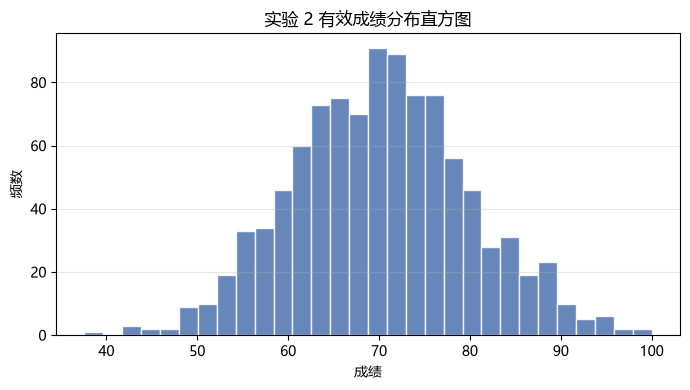

In [18]:
valid_scores = scores_df["成绩"].dropna().to_numpy()

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(valid_scores, bins=30, color="#4C72B0", edgecolor="white", alpha=0.85)
ax.set_title("实验 2 有效成绩分布直方图")
ax.set_xlabel("成绩")
ax.set_ylabel("频数")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

**说明：** 直方图把有效成绩分成 30 个区间，横轴为成绩、纵轴为频数。分布整体以 70 附近为中心，两侧大致对称；由于 `clip` 的作用，所有值都落在 0–100 内，其中 2 个超过 100 的样本被截断为 100，最小值约为 37.6，没有样本被截断到 0。

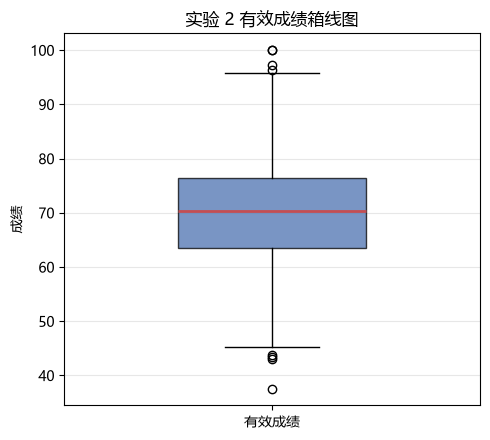

In [19]:
fig, ax = plt.subplots(figsize=(5, 4.5))
box = ax.boxplot(valid_scores, patch_artist=True, widths=0.45,
                 medianprops={"color": "#C44E52", "linewidth": 2})
box["boxes"][0].set_facecolor("#4C72B0")
box["boxes"][0].set_alpha(0.75)
ax.set_title("实验 2 有效成绩箱线图")
ax.set_ylabel("成绩")
ax.set_xticks([1])
ax.set_xticklabels(["有效成绩"])
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

**说明：** 箱线图展示中位数、上下四分位数、须的范围和离群点。箱体（Q1–Q3）约为 63.5–76.5，中位数约 70.3，与直方图的中心一致；上下须延伸到约 44–96，须之外共有 8 个离群值（圆点）。

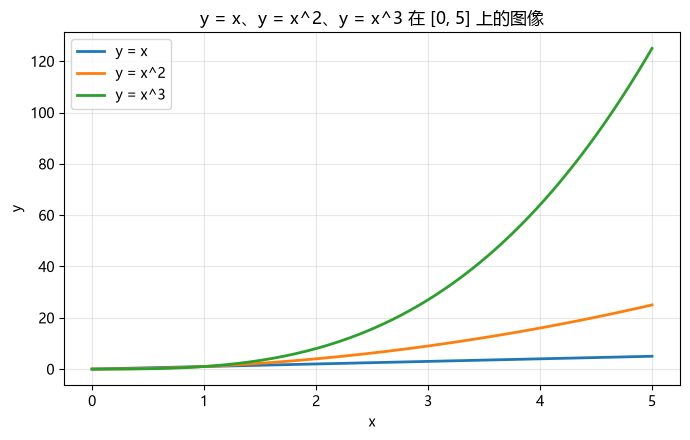

In [20]:
x = np.linspace(0, 5, 200)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(x, x, label="y = x", linewidth=2)
ax.plot(x, x ** 2, label="y = x^2", linewidth=2)
ax.plot(x, x ** 3, label="y = x^3", linewidth=2)
ax.set_title("y = x、y = x^2、y = x^3 在 [0, 5] 上的图像")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**说明：** 三条曲线都过原点，且随 x 增大而增大。在 `0 ≤ x ≤ 1` 时 `x^3 ≤ x^2 ≤ x`，在 `x ≥ 1` 后大小关系反转，`x^3` 增长最快；三条曲线在 `x = 1` 处都等于 1。图例、标题和坐标轴标签均已设置。

## 实验 4：pandas Series、DataFrame 与内存中的 CSV 读写

### 1. 创建 DataFrame 并计算总分、平均分

用给定模拟数据创建 DataFrame，行索引为姓名；计算 `Total`（三科总分）和 `Average`（三科平均分）两列，输出行索引、列名、前 3 行和基本统计信息。

In [21]:
records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82],
}
df = pd.DataFrame(records).set_index("Name")
df["Total"] = df[["Math", "English", "Python"]].sum(axis=1)
df["Average"] = df[["Math", "English", "Python"]].mean(axis=1)

print("行索引:", df.index.tolist())
print("列名:", df.columns.tolist())
print("\n前 3 行:")
print(df.head(3))
print("\n基本统计信息:")
print(df.describe())

行索引: ['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']
列名: ['Group', 'Math', 'English', 'Python', 'Total', 'Average']

前 3 行:
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333

基本统计信息:
            Math    English     Python       Total    Average
count   6.000000   6.000000   6.000000    6.000000   6.000000
mean   79.833333  80.833333  83.666667  244.333333  81.444444
std     9.907909   9.662643   8.547904   25.781130   8.593710
min    65.000000  68.000000  70.000000  208.000000  69.333333
25%    73.750000  74.000000  80.500000  225.750000  75.250000
50%    81.500000  81.000000  84.000000  250.000000  83.333333
75%    87.000000  88.750000  88.250000  263.000000  87.666667
max    91.000000  92.000000  95.000000  273.000000  91.000000


**说明：** `set_index("Name")` 把姓名设为行索引；`sum(axis=1)` 沿行方向求和得到总分，`mean(axis=1)` 得到平均分。`df.describe()` 默认对数值列给出计数、均值、标准差、最小值、四分位数和最大值。

### 2. 用 `loc` 和 `iloc` 读取记录并筛选

分别用 `loc` 和 `iloc` 读取 Carol 的记录，并筛选平均分不低于 80 的学生。

In [22]:
print("loc['Carol']（按行标签）:")
print(df.loc["Carol"])
print("\niloc[2]（按行位置，第 3 行）:")
print(df.iloc[2])
print("\n平均分不低于 80 的学生:")
print(df[df["Average"] >= 80])

loc['Carol']（按行标签）:
Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object

iloc[2]（按行位置，第 3 行）:
Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object

平均分不低于 80 的学生:
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Carol     B    91       85      89    265  88.333333
Eva       A    79       92      86    257  85.666667
Frank     B    84       77      82    243  81.000000


**说明：** `loc` 按行/列标签访问，`iloc` 按整数位置访问；Carol 是第 3 行，标签为 `"Carol"`，位置为 `2`，所以两种写法返回同一条记录。布尔条件 `df["Average"] >= 80` 生成行掩码，筛选出平均分不低于 80 的学生（Alice、Carol、Eva、Frank）。

### 3. 列均值与行均值

分别用 `mean(axis=0)` 和 `mean(axis=1)` 计算三科成绩的列均值和每名学生的行均值。

In [23]:
subject_cols = ["Math", "English", "Python"]
col_mean = df[subject_cols].mean(axis=0)
row_mean = df[subject_cols].mean(axis=1)

print("列均值 mean(axis=0):")
print(col_mean)
print("\n行均值 mean(axis=1):")
print(row_mean)
print("\n与 Average 列一致:", np.allclose(row_mean, df["Average"]))

列均值 mean(axis=0):
Math       79.833333
English    80.833333
Python     83.666667
dtype: float64

行均值 mean(axis=1):
Name
Alice    91.000000
Bob      73.333333
Carol    88.333333
David    69.333333
Eva      85.666667
Frank    81.000000
dtype: float64

与 Average 列一致: True


**说明：** `axis=0` 沿行方向压缩，得到每一列（每科）的均值；`axis=1` 沿列方向压缩，得到每一行（每名学生）的均值，正好等于 `Average` 列。可以用 `np.allclose` 验证两种计算结果一致。

### 4. `apply`、`agg` 与 `rank`

用 `apply()` 计算每名学生的三科最高分；用 `agg()` 一次得到每科的最小值、均值和最大值；任选一列用 `rank()` 给学生排名。

In [24]:
df["MaxScore"] = df[subject_cols].apply(np.max, axis=1)
agg_result = df[subject_cols].agg(["min", "mean", "max"])
df["MathRank"] = df["Math"].rank(ascending=False, method="min").astype(int)

print("每名学生三科最高分:")
print(df[["Math", "English", "Python", "MaxScore"]])
print("\n每科最小值、均值和最大值:")
print(agg_result)
print("\n按 Math 排名（分数高者名次小）:")
print(df[["Math", "MathRank"]].sort_values("Math", ascending=False))

每名学生三科最高分:
       Math  English  Python  MaxScore
Name                                  
Alice    88       90      95        95
Bob      72       68      80        80
Carol    91       85      89        91
David    65       73      70        73
Eva      79       92      86        92
Frank    84       77      82        84

每科最小值、均值和最大值:
           Math    English     Python
min   65.000000  68.000000  70.000000
mean  79.833333  80.833333  83.666667
max   91.000000  92.000000  95.000000

按 Math 排名（分数高者名次小）:
       Math  MathRank
Name                 
Carol    91         1
Alice    88         2
Frank    84         3
Eva      79         4
Bob      72         5
David    65         6


**说明：** `apply(np.max, axis=1)` 对每一行取最大值；`agg(["min", "mean", "max"])` 一次返回每列的三种统计量；`rank(ascending=False, method="min")` 让分数越高名次越小，并列时使用最小名次。排名列用 `astype(int)` 转成整数便于阅读。

### 5. 分组统计与 `transform`

按 `Group` 分组，统计每组人数和三科平均分；再用 `transform('mean')` 为每行增加其所在组的 Python 平均分。

In [25]:
group_summary = df.groupby("Group").agg(
    人数=("Math", "size"),
    Math均值=("Math", "mean"),
    English均值=("English", "mean"),
    Python均值=("Python", "mean"),
)
df["GroupPythonMean"] = df.groupby("Group")["Python"].transform("mean")

print("分组统计:")
print(group_summary)
print("\n每名学生及其所在组的 Python 平均分:")
print(df[["Group", "Python", "GroupPythonMean"]])

分组统计:
       人数     Math均值  English均值   Python均值
Group                                     
A       3  79.666667  83.333333  87.000000
B       3  80.000000  78.333333  80.333333

每名学生及其所在组的 Python 平均分:
      Group  Python  GroupPythonMean
Name                                
Alice     A      95        87.000000
Bob       A      80        87.000000
Carol     B      89        80.333333
David     B      70        80.333333
Eva       A      86        87.000000
Frank     B      82        80.333333


**说明：** `groupby("Group").agg(...)` 按组汇总，`size` 统计每组行数，`mean` 计算各组三科均值。`transform("mean")` 与 `agg` 不同：它把组均值“广播”回原表的每一行，因此结果长度与原表相同，可以直接赋值为新列。

### 6. 用 `filter()` 保留 Python 平均分不低于 80 的组

用 `filter()` 保留 Python 平均分不低于 80 的组，输出保留的组和学生。

In [26]:
filtered = df.groupby("Group").filter(lambda g: g["Python"].mean() >= 80)

print("各组的 Python 平均分:")
print(df.groupby("Group")["Python"].mean())
print("\n保留的组:", sorted(filtered["Group"].unique().tolist()))
print("\n保留组中的学生:")
print(filtered[["Group", "Python", "Average"]])

各组的 Python 平均分:
Group
A    87.000000
B    80.333333
Name: Python, dtype: float64

保留的组: ['A', 'B']

保留组中的学生:
      Group  Python    Average
Name                          
Alice     A      95  91.000000
Bob       A      80  73.333333
Carol     B      89  88.333333
David     B      70  69.333333
Eva       A      86  85.666667
Frank     B      82  81.000000


**说明：** `filter` 的函数接收每个子表，返回布尔值；只有返回 `True` 的组会被保留，且保留的是该组的全部行。A 组 Python 平均分为 87.0，B 组为 80.33，都不低于 80，所以两组都被保留。如果某组均值低于 80，该组的所有学生都不会出现在结果中。

### 7. 协方差矩阵与相关系数矩阵

计算三科成绩之间的协方差矩阵和皮尔逊相关系数矩阵，选择一对科目解释协方差符号与相关系数大小的含义。

In [27]:
cov_matrix = df[subject_cols].cov()
corr_matrix = df[subject_cols].corr()

print("协方差矩阵:")
print(cov_matrix.round(4))
print("\n皮尔逊相关系数矩阵:")
print(corr_matrix.round(4))

协方差矩阵:
            Math  English   Python
Math     98.1667  62.5667  74.9333
English  62.5667  93.3667  62.5333
Python   74.9333  62.5333  73.0667

皮尔逊相关系数矩阵:
           Math  English  Python
Math     1.0000   0.6535  0.8848
English  0.6535   1.0000  0.7571
Python   0.8848   0.7571  1.0000


**说明：** 协方差矩阵的对角线是各科方差，非对角线是两科协方差；协方差为正表示两科成绩倾向于同向变化，为负表示反向变化，但数值大小受量纲影响，不便于跨科目比较。相关系数矩阵是标准化后的协方差，取值在 `[-1, 1]`：绝对值越接近 1 线性关系越强，越接近 0 线性关系越弱。以 Math 与 Python 为例，协方差为正，说明数学成绩高的学生 Python 成绩也倾向于高；相关系数为正且绝对值较大，说明两者有较强的正线性相关（具体数值见上方输出）。

### 补充：内存中的 CSV 读写

本节标题包含“内存中的 CSV 读写”。下面用 `io.StringIO` 在内存中完成一次 `to_csv` / `read_csv` 往返，不写入磁盘。

In [28]:
import io

buffer = io.StringIO()
df.to_csv(buffer)
buffer.seek(0)
df_from_csv = pd.read_csv(buffer, index_col=0)

print("从内存中的 CSV 读回的前 3 行:")
print(df_from_csv.head(3))
print("\n形状是否一致:", df_from_csv.shape == df.shape)

从内存中的 CSV 读回的前 3 行:
      Group  Math  English  Python  Total    Average  MaxScore  MathRank  \
Name                                                                       
Alice     A    88       90      95    273  91.000000        95         2   
Bob       A    72       68      80    220  73.333333        80         5   
Carol     B    91       85      89    265  88.333333        91         1   

       GroupPythonMean  
Name                    
Alice        87.000000  
Bob          87.000000  
Carol        80.333333  

形状是否一致: True


**说明：** `df.to_csv(buffer)` 把表格写成 CSV 文本并保存在 `StringIO` 缓冲区中，`buffer.seek(0)` 把读写位置移回开头，`pd.read_csv(buffer, index_col=0)` 再从同一块内存读回 DataFrame。整个过程没有创建磁盘文件，读回后的形状与原表一致。

## 小结

- 完成了 NumPy 数组、dtype、reshape、索引与布尔掩码，随机抽样、统计量与缺失值处理，SciPy 线性方程/求根/优化/t 检验，Matplotlib 直方图/箱线图/折线图，以及 pandas 的 DataFrame 创建、索引、筛选、聚合、分组和相关性分析。
- 所有随机过程固定 `np.random.seed(42)`，结果可复现。
- 图表均包含标题、坐标轴标签，折线图包含图例，并直接内嵌在 Notebook 中。
- 运行环境为 conda 虚拟环境 `dpenv`，未使用 base 环境。